In [1]:
import matplotlib.pyplot as plt
import numpy as np
import json

%reload_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
from methods_mat_fac import *
from oracles_mat_fac import *
from methods import gradient_method, mf_gladssn, mf_leapssn, cubic_newton
from utils import run_methods, plot_figures

# Matrix Factorisation
#### Run multiple seeds

### Parameters

In [3]:
all_seeds_histories = {}
# seeds_to_try = [11]
seeds_to_try = np.random.randint(0, 1000, size=20)   
print("Trying seeds: ", seeds_to_try)
current_seed_index = 0
for seed in seeds_to_try:
    print("Current seed index: ", current_seed_index)
    np.random.seed(seed)
    print("Running seed: ", seed)

    # Ground truth
    m, n, r = 200, 100, 12
    U_true = np.random.rand(m, r)
    V_true = np.random.rand(n, r)
    M_clean = U_true @ V_true.T

    # Noisy observed matrix
    noise = 0.0
    M_obs = M_clean + noise * np.random.randn(m, n)

    # Oracle params
    lam = 1 * 1e-2
    mu = 100

    # Initialise
    x_0 = 0.5 * np.random.randn(m * r + n * r)


    # Metrics function (same for both)
    def make_metric_fn(oracle):
        return lambda z: mf_terms_and_metrics(
            oracle, z, M_clean=M_clean, U_true=U_true, V_true=V_true
        )


    oracle = PositiveMatrixFactorization(M_obs, r=r, lam=lam, mu=mu)

    number_of_iterations = 12000 #100#6500  # 6500  # 12000 #8000 #350

    methods_to_run = {
        "Gradient Method": (gradient_method, (oracle, x_0), dict(max_iter=3000000)), # 3000000
        "LeAP-SSN": (
        mf_leapssn,
        (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=1,
            warnings=True,
            lss_tol=1e-9,
            lss_method="minres",
            use_gauss_newton=False,
        ),
    ),
            "GLAd-SSN, p=0.2": (
            mf_gladssn,
            (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=1,
                warnings=True,
                p=0.2,
                lss_tol=1e-9,
                lss_method="minres",
                use_gauss_newton=False,
            ),
        ),
            "GLAd-SSN, p=0.4": (
            mf_gladssn,
            (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=1,
                warnings=True,
                p=0.4,
                lss_tol=1e-9,
                lss_method="minres",
                use_gauss_newton=False,
            ),
        ),
        "GLAd-SSN, p=0.5": (
            mf_gladssn,
            (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=1,
                warnings=True,
                p=0.5,
                lss_tol=1e-9,
                lss_method="minres",
                use_gauss_newton=False,
            ),
        ),
        "GLAd-SSN, p=0.6": (
            mf_gladssn,
            (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=1,
                warnings=True,
                p=0.6,
                lss_tol=1e-9,
                lss_method="minres",
                use_gauss_newton=False,
            ),
        ),
            "GLAd-SSN, p=0.8": (
            mf_gladssn,
            (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=1,
                warnings=True,
                p=0.8,
                lss_tol=1e-9,
                lss_method="minres",
                use_gauss_newton=False,
            ),
        ),
        
    }
    histories = run_methods(methods_to_run, oracle, x_0)
    all_seeds_histories[seed] = histories
    filename = "data/history_seed_" + str(seed) + ".json"
    with open(filename, 'w') as f:
        json.dump(histories, f)
    current_seed_index += 1

Trying seeds:  [549 498 483  33 528 989 465 344 153 867 107 424 998 230 996 229 725 911
 418 146]
Current seed index:  0
Running seed:  549

Running Gradient Method...
Time: 468.051 s

Running LeAP-SSN...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
Iteration  5000
Iteration  5500
Iteration  6000
Iteration  6500
Iteration  7000
Iteration  7500
Iteration  8000
Iteration  8500
Iteration  9000
Iteration  9500
Iteration  10000
Iteration  10500
Iteration  11000
Iteration  11500
Iteration  12000
No of backtracks:  11993
Time: 529.529 s

Running GLAd-SSN, p=0.2...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
Iteration  5000
Iteration  5500
Iteration  6000
Iteration  6500
Iteration  7000
Iteration  7500
Iteration  8000
Iteration  8500
Iteration  9000
Iteration  9500
Iteration

/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:232: RuntimeWarning: overflow encountered in scalar add
  tnorm2 += alfa**2 + oldb**2 + beta**2
/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:280: RuntimeWarning: invalid value encountered in scalar multiply
  epsx = Anorm * ynorm * eps
/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:281: RuntimeWarning: invalid value encountered in scalar multiply
  epsr = Anorm * ynorm * rtol


Iteration  11000
Iteration  11500
Iteration  12000
No of backtracks:  12263
Time: 475.571 s

Running GLAd-SSN, p=0.8...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
Iteration  5000
Iteration  5500
Iteration  6000
Iteration  6500
Iteration  7000
Iteration  7500
Iteration  8000
Iteration  8500
Iteration  9000
Iteration  9500
Iteration  10000
Iteration  10500
Iteration  11000
Iteration  11500
Iteration  12000
No of backtracks:  12010
Time: 484.905 s
Current seed index:  1
Running seed:  498

Running Gradient Method...
Time: 456.217 s

Running LeAP-SSN...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
Iteration  2000
Iteration  2500
Iteration  3000
Iteration  3500
Iteration  4000
Iteration  4500
W: adaptive_iterations_exceeded, k = 4814
W: adaptive_iterations_exceeded, k = 4815
W: adaptive_iterations_exceeded, k = 4816
W: adaptive_iterations_exceeded, k = 4817
Iterati

/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:232: RuntimeWarning: overflow encountered in scalar power
  tnorm2 += alfa**2 + oldb**2 + beta**2
/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:296: RuntimeWarning: invalid value encountered in scalar divide
  test2 = root / Anorm            # ||Ar|| / (||A|| ||r||)
/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-essen.sciebo.de/Code/Lazy Hessian code/.venv-1/lib/python3.14/site-packages/scipy/sparse/linalg/_isolve/minres.py:255: RuntimeWarning: invalid value encountered in scalar divide
  sn = beta / gamma             # sk
/Users/amal/Library/CloudStorage/Sciebo-cbs853q@uni-duisburg-essen.de@uni-duisburg-esse

W: not all finite delta_x at k = 6227 i = 26
W: not all finite delta_x at k = 6227 i = 27
W: not all finite delta_x at k = 6227 i = 28
W: not all finite delta_x at k = 6227 i = 29
W: not all finite delta_x at k = 6227 i = 30
W: not all finite delta_x at k = 6227 i = 31
W: not all finite delta_x at k = 6227 i = 32
W: not all finite delta_x at k = 6227 i = 33
W: not all finite delta_x at k = 6227 i = 34
W: not all finite delta_x at k = 6227 i = 35
W: not all finite delta_x at k = 6227 i = 36
W: not all finite delta_x at k = 6227 i = 37
W: not all finite delta_x at k = 6227 i = 38
W: not all finite delta_x at k = 6227 i = 39
W: not all finite delta_x at k = 6227 i = 40
W: not all finite delta_x at k = 6227 i = 41
W: not all finite delta_x at k = 6227 i = 42
W: not all finite delta_x at k = 6227 i = 43
W: not all finite delta_x at k = 6227 i = 44
W: not all finite delta_x at k = 6227 i = 45
W: not all finite delta_x at k = 6227 i = 46
W: not all finite delta_x at k = 6227 i = 47
W: not all

In [4]:
# print(histories.keys())
# print(histories["Gradient Method"].keys())
# print(histories["GLAd-SSN, p=0.2"].keys())

template_seed = seeds_to_try[0]

averaged_history = {
    method_name: {
        measure: np.zeros_like(
            np.array(all_seeds_histories[template_seed][method_name][measure]), dtype=np.float64
        )
        for measure in all_seeds_histories[template_seed][method_name]
    }
    for method_name in all_seeds_histories[template_seed]
}

print(averaged_history.keys())
 

dict_keys(['Gradient Method', 'LeAP-SSN', 'GLAd-SSN, p=0.2', 'GLAd-SSN, p=0.4', 'GLAd-SSN, p=0.5', 'GLAd-SSN, p=0.6', 'GLAd-SSN, p=0.8'])


In [5]:
# print(all_seeds_histories.keys())
# print(all_seeds_histories[10].keys())
# print(all_seeds_histories[10]["GLAd-SSN, p=0.5"].keys())
# print(all_seeds_histories[10]["GLAd-SSN, p=0.5"]["func"])
# print(type(all_seeds_histories[10]["GLAd-SSN, p=0.5"]))

def add_common(a, b):
    n = min(len(a), len(b))
    return a[:n] + b[:n]


for seed in seeds_to_try:
    for method_name in all_seeds_histories[seed].keys():
        for measure in all_seeds_histories[seed][method_name].keys():
            # print(method_name)   
            # print(measure)
            # print(len(all_seeds_histories[10][method_name][measure]))
            # print(len(all_seeds_histories[20][method_name][measure]))
            averaged_history[method_name][measure] =  add_common(np.array(averaged_history[method_name][measure]), np.array(all_seeds_histories[seed][method_name][measure]))
# Divide
for method_name in averaged_history:
    for measure in averaged_history[method_name]:
        averaged_history[method_name][measure] /= len(seeds_to_try)
        averaged_history[method_name][measure] = averaged_history[method_name][measure].tolist()  # Convert to list for JSON serialization

filename="data/averaged_history"
for seed in seeds_to_try:
    filename = filename + "_" + str(seed)
filename = filename + ".json"

print(filename)
with open(filename, 'w') as f:
    json.dump(averaged_history, f)

data/averaged_history_549_498_483_33_528_989_465_344_153_867_107_424_998_230_996_229_725_911_418_146.json


# Code for plotting

last func residual of Gradient Method: 0.016794109860048145
last func residual of LeAP-SSN: 0.0
last func residual of GLAd-SSN, p=0.2: 0.0005835167042818057
last func residual of GLAd-SSN, p=0.4: 0.001699843664780154
last func residual of GLAd-SSN, p=0.5: 0.0016403542225011947
last func residual of GLAd-SSN, p=0.6: 0.0059906629376742515
last func residual of GLAd-SSN, p=0.8: 0.000429907873593649
last func residual of Gradient Method: 0.0004395148786187529
last func residual of LeAP-SSN: 2.408375326536199e-08
last func residual of GLAd-SSN, p=0.2: 1.6075134791466285e-06
last func residual of GLAd-SSN, p=0.4: 2.3179015946812685e-06
last func residual of GLAd-SSN, p=0.5: 2.390902261238756e-07
last func residual of GLAd-SSN, p=0.6: 0.0006619709921501474
last func residual of GLAd-SSN, p=0.8: 2.282045628572906e-05


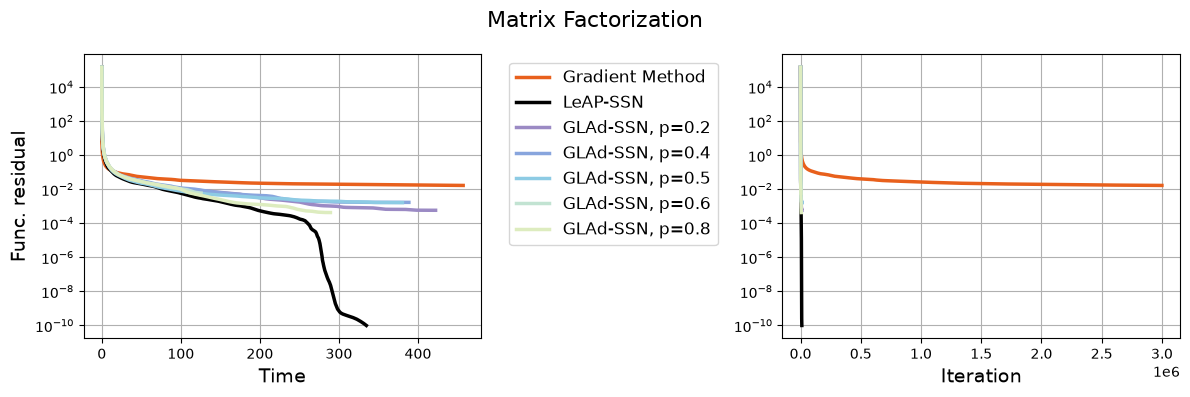

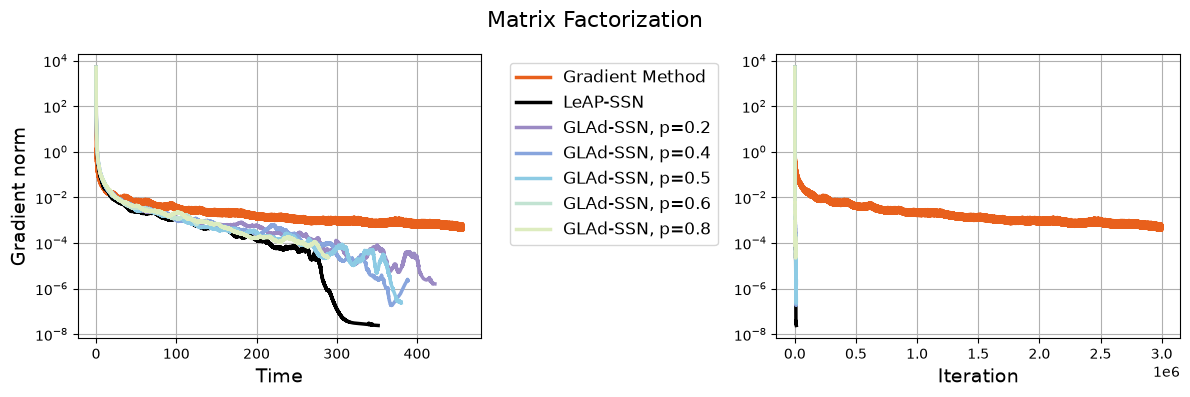

In [7]:
histories = averaged_history
resid = np.array(list(histories.values())[1]["func"])
resid_2 = np.array(list(histories.values())[1]["func_at_lssolve"])


line_widths = [2.5] * len(methods_to_run)
line_styles = ["-"] * len(methods_to_run)

gradient_method_color = "#E8601C"
cubic_newton_color = "gold"
leapssn_color = "black"
gladssn_color = "#9B8AC4"
gladssn_1_color = "#88A5DD"
gladssn_2_color = "#8DCBE4"
gladssn_3_color = "#C2E3D2"
gladssn_4_color = "#DDECBF"
# gladssn_5_color = "#F2E1D0"
colors = [gradient_method_color, leapssn_color, gladssn_color, gladssn_1_color, gladssn_2_color, gladssn_3_color, gladssn_4_color]
marker_cycle = [
"None",   # None Gradient Method
"*",   # star Cubic Newton
"s",   # square LeapSSN
"^",   # triangle up GladSSN
"D",   # diamond GladSSN second
"x",   # x GladSSN third
"v",   # triangle down GladSSN fourth
"h",   # hexagon GladSSN fifth
] 


list_of_mins = [np.min(history["func"]) for history in histories.values()]
mn_func = min(list_of_mins)
plot_figures(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,  # mn_func,
    threshold=1e-10,
    suptitle=("Matrix Factorization"),
    which_measure_2="func",
    max_iter=1000,
)
plot_figures(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=0,
    threshold=1e-10,
    suptitle=("Matrix Factorization"),
    max_iter=1000,
    which_measure_1="grad_norm",
    which_measure_2="grad_norm",
    # which_measure_2="grad_norm_at_lssolve",
    ylabel="Gradient norm",
)

plt.show()

# Plots for the paper

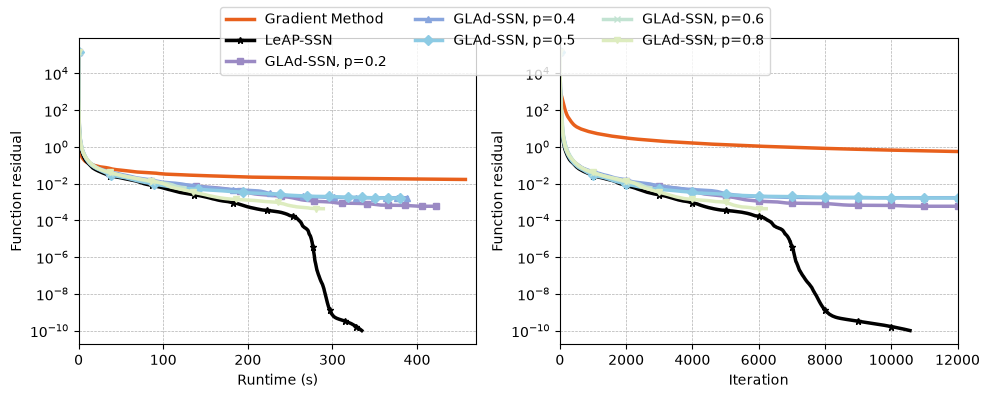

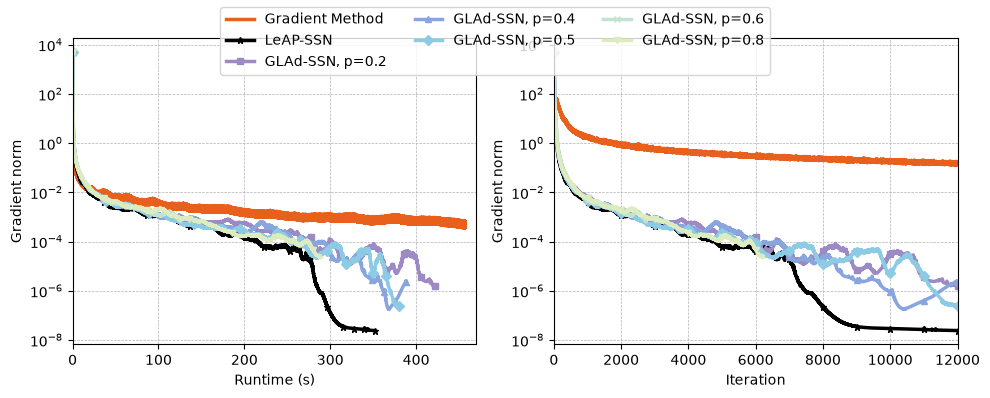

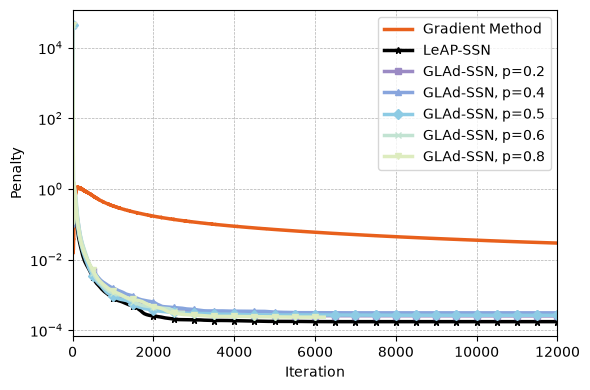

In [10]:
from utils import plot_for_paper_2, plot_for_paper_penalty
markevery_numbers = [50000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]

plot_for_paper_2(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Plots"),
    max_iter=12000,
    which_measure="func",
    marker_cycle=marker_cycle,
    markevery_numbers=markevery_numbers,
)
plot_for_paper_2(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Plots"),
    max_iter=12000,
    which_measure="grad_norm",
    marker_cycle=marker_cycle,
    markevery_numbers=markevery_numbers,
)
plot_for_paper_penalty(
    list(histories.values()),
    list(histories.keys()),
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    marker_cycle=marker_cycle,
    max_time=12000,
)

In [9]:
# Save the averaged series used by the MF plots.
import pickle

plot_keys = ("func", "time", "grad_norm", "penalty")
plot_histories = {
    label: {key: np.asarray(history[key]) for key in plot_keys if key in history}
    for label, history in averaged_history.items()
}
with open("mf_results_multiple.pkl", "wb") as result_file:
    pickle.dump({"histories": plot_histories, "labels": list(averaged_history)}, result_file)
print("Saved plotting data to mf_results_multiple.pkl")

Saved plotting data to mf_results_multiple.pkl
